# 13 — Deconvolution: from voltage back to electric field

Notebooks 03 to 06 go from a shower's electric field to the voltage the antennas
record. This one goes back: given the voltages, it recovers the field with a
**Wiener filter**, the linear estimate with the smallest mean squared error.

That is `grand.recon.deconvolution`. It comes in two layers, and the notebook shows
both:

- the **low-level interface** works on arrays, one detection unit at a time:
  build the unit's response, choose a noise model and a prior, deconvolve.
  Sections 2 to 6.
- the **AOI interface** takes an `Event` read with `EventList` and does every unit
  at once. Sections 7 to 10.

The notebook simulates its own voltages, from the ZHAireS shower committed in
`sim2root/Common`, so that every result can be compared with the field it came
from.

**What this does not show**: that it works on measured data, or on other
geometries. Everything here, and in the tests, rests on one inclined shower
(zenith 79°) simulated with the very antenna and RF-chain models the deconvolution
uses. Measured voltages also come in ADC counts, which have to be converted to µV
first.

**Prerequisites**: the `grand-dev` environment and the model data
(`data/detector`, `data/noise`), which `python data/download_data_grand.py` fetches.

## 1. The problem, before any code

For one unit, at each frequency $\nu$, the three arms (SN, EW, UP) see

$$\vec V(\nu) = \mathbf T(\nu)\,\vec E(\nu) + \vec N(\nu),
\qquad T_{kj} = RF_k(\nu)\,L_{kj}(\theta, \phi, \nu)$$

with $L$ the effective length in the direction of the shower maximum, $RF$ the RF
chain and $\vec N$ the noise. With $\mathbf C_E$ and $\mathbf C_N$ the covariances
of field and noise, the Wiener estimate and its covariance are

$$\hat{\vec E} = \left[\mathbf C_E^{-1} + \mathbf T^\dagger \mathbf C_N^{-1}\mathbf T\right]^{-1}
\mathbf T^\dagger \mathbf C_N^{-1}\vec V, \qquad
\mathbf C_{\hat E} = \left[\mathbf C_E^{-1} + \mathbf T^\dagger \mathbf C_N^{-1}\mathbf T\right]^{-1}$$

Three things follow, and they come back in every section:

1. **The antenna sees two components, not three.** $L$ has components along
   $\vec u_\theta$ and $\vec u_\phi$ only, so $\mathbf T\vec n = 0$, with $\vec n$ the
   line of sight. The field along it cannot be recovered.
2. **Only the band comes back**: 30–250 MHz, where the antenna tables and the noise
   model are defined.
3. **The prior trades error for bias.** No prior gives the unbiased least-squares
   inverse; a finite one lowers the error but also the peak of the pulse.

| Layer | What you use | What it does |
|---|---|---|
| low level | `DetectorResponse` | builds $\mathbf T$, with the simulation's own antenna and RF-chain code |
| | `GalacticNoise`, `WhiteNoise`, `MeasuredNoise` | the noise power spectrum |
| | `geomagnetic_polarization` | the direction $\vec v\times\vec B$ expected for an air shower |
| | `WienerDeconvolution` | the filter, with its prior on polarization and level |
| AOI | `EventDeconvolver` | all of the above, for every unit of an `Event` |

In [1]:
import os
import pathlib
import tempfile
from functools import partial

import numpy as np
import scipy.fft as sf
import matplotlib.pyplot as plt

import grand
from grand import Efield2Voltage

SAMPLE = (pathlib.Path(grand.__file__).parents[1]
          / "sim2root/Common/sim_Xiaodushan_20221026_000000_RUN1_CD_ZHAireS_0000")
LST = 18.0          # local sidereal time of the Galactic noise, in hours


def simulate(noise, directory=None):
    """Voltages of the sample's first event, as Efield2Voltage computes them."""
    sim = Efield2Voltage(str(SAMPLE), "voltage_1618-13790_L0_0000.root",
                         output_directory=directory or tempfile.mkdtemp(),
                         seed=1, efield_level=0)
    sim.params.update(add_noise=noise, add_rf_chain=True, lst=LST)
    sim.compute_voltage_event(0)
    sim.final_resample()
    return sim


clean, noisy = simulate(False), simulate(True)
print("event %d: %d units, %d samples of %.1f ns"
      % (clean.event_number, clean.nb_du, clean.sig_size, clean.dt_ns[0]))
print("zenith %.1f deg, azimuth %.1f deg, geomagnetic inclination %.1f deg"
      % (clean.shower.zenith, clean.shower.azimuth, clean.shower.magnetic_field[0]))

event 13790: 44 units, 8192 samples of 0.5 ns
zenith 79.4 deg, azimuth 310.0 deg, geomagnetic inclination 61.6 deg


`clean` has no noise and serves as the truth; `noisy` is what we deconvolve. Both
keep their arrays in memory: `vout` is the voltage in µV, `vout_f` its spectrum,
`traces` the simulated field in µV/m.

**Why not the voltage file already in `sim2root/Common`?** It was written in 2024
by an older chain, and differs from today's by a factor of 0.45 to 3.7 depending
on the band and the arm. Deconvolving it with today's models does not give its
field back. Any test of the deconvolution has to simulate its voltages afresh.

Most units of this shower are below the noise. The strongest one is used
throughout the low-level part:

voltage signal-to-noise ratio: median 0.20, 13 units above 15; strongest: unit 9 (du_id 177), 73


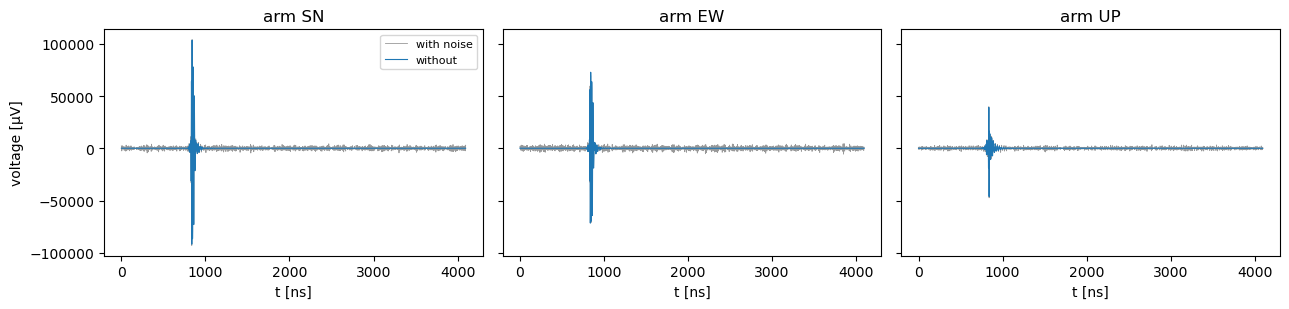

In [2]:
noise_only = noisy.vout - clean.vout
snr = np.abs(clean.vout).max(axis=(1, 2)) / noise_only.std(axis=2).max(axis=1)
du = int(np.argmax(snr))
print("voltage signal-to-noise ratio: median %.2f, %d units above 15; strongest: unit %d (du_id %d), %.0f"
      % (np.median(snr), np.sum(snr > 15), du, clean.du_id[du], snr[du]))

t_ns = np.arange(clean.sig_size) * clean.dt_ns[0]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for arm, (ax, name) in enumerate(zip(axes, ("SN", "EW", "UP"))):
    ax.plot(t_ns, noisy.vout[du, arm], lw=0.6, color="0.6", label="with noise")
    ax.plot(t_ns, clean.vout[du, arm], lw=0.8, color="C0", label="without")
    ax.set_title("arm %s" % name)
    ax.set_xlabel("t [ns]")
axes[0].set_ylabel("voltage [µV]")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

# Part I — the low-level interface

## 2. The response of one unit

`DetectorResponse` holds the antenna tables and the RF chain. Given a unit's
position, the shower and a frequency axis, it returns the transfer matrix and the
line of sight from the shower maximum. It evaluates the effective length with the
same code `Efield2Voltage` uses, so it inverts exactly what the simulation applied.
Pass `antenna_model=` to reuse tables already loaded: they are slow to load.

transfer matrix: (4097, 3, 3) (frequency, arm, field component)
line of sight in the shower frame (x north, y west, z up): [-0.636  0.747 -0.193]
T E against the simulation's spectrum: largest difference 8.3e-08 of the peak


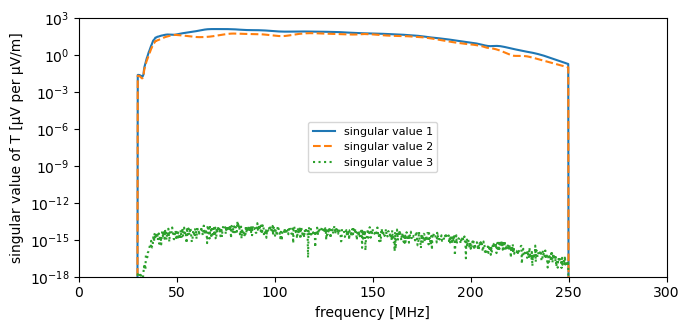

In [3]:
from grand.recon.deconvolution import DetectorResponse

detector = DetectorResponse(antenna_model=clean.ant_model)      # GP300 tables, default RF chain
transfer, line_of_sight = detector.transfer_matrix(clean.du_pos[du], clean.evt_shower,
                                                   clean.freqs_mhz)
print("transfer matrix:", transfer.shape, "(frequency, arm, field component)")
print("line of sight in the shower frame (x north, y west, z up):", np.round(line_of_sight, 3))

# Applied to the simulated field, it gives back the simulated voltage
field_f = sf.rfft(clean.traces[du].astype(float), n=clean.fft_size, axis=1).T
voltage_f = np.einsum("fkj,fj->fk", transfer, field_f)
print("T E against the simulation's spectrum: largest difference %.1e of the peak"
      % (np.abs(voltage_f - clean.vout_f[du].T).max() / np.abs(clean.vout_f[du]).max()))

singular = np.linalg.svd(transfer, compute_uv=False)
fig, ax = plt.subplots(figsize=(7, 3.4))
for i, style in enumerate(("-", "--", ":")):
    ax.semilogy(clean.freqs_mhz, singular[:, i] + 1e-30, style, label="singular value %d" % (i + 1))
ax.set_xlim(0, 300)
ax.set_ylim(1e-18, 1e3)
ax.set_xlabel("frequency [MHz]")
ax.set_ylabel("singular value of T [µV per µV/m]")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The third singular value sits at the level of rounding: the matrix has **rank 2**.
It sends the line of sight to zero, and that component of the field leaves no
trace in the voltage. Outside 30–250 MHz the tables give nothing at all.

## 3. The noise

`GalacticNoise` is the model `Efield2Voltage` draws its noise from, without the
random draw, and passed through the RF chain. It is defined over the band of its
tables, so the response built with it is restricted to that band. The noise the
simulation actually added is known here, so the model can be checked:

band of the response: 30.0 to 249.8 MHz, 901 of 4097 bins
noise drawn by the simulation / model, mean over the band, per arm: [0.991 0.996 0.997]


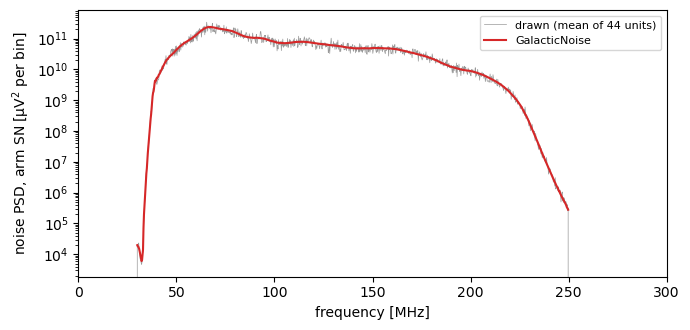

In [4]:
from grand.recon.deconvolution import GalacticNoise

noise_model = GalacticNoise(lst=LST)
response = detector.response(clean.du_pos[du], clean.evt_shower, clean.freqs_mhz, noise_model)
band = response.band
print("band of the response: %.1f to %.1f MHz, %d of %d bins"
      % (clean.freqs_mhz[band][0], clean.freqs_mhz[band][-1], band.sum(), band.size))

drawn = np.mean(np.abs(noisy.vout_f - clean.vout_f) ** 2, axis=0).T    # over the 44 units
print("noise drawn by the simulation / model, mean over the band, per arm:",
      np.round(drawn[band].mean(axis=0) / response.noise_psd[band].mean(axis=0), 3))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(clean.freqs_mhz, drawn[:, 0], lw=0.5, color="0.6", label="drawn (mean of 44 units)")
ax.semilogy(clean.freqs_mhz[band], response.noise_psd[band, 0], color="C3", label="GalacticNoise")
ax.set_xlim(0, 300)
ax.set_xlabel("frequency [MHz]")
ax.set_ylabel(r"noise PSD, arm SN [µV$^2$ per bin]")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Two other models exist, for when the noise is not the simulation's:

- `WhiteNoise(sigma)`, the same power at every frequency;
- `MeasuredNoise(traces, t_bin_ns)`, estimated by Welch's method from traces that
  hold no signal, such as forced triggers. Section 6 uses it.

## 4. Deconvolving one unit

`WienerDeconvolution(signal_psd, mode)` is the method. `deconvolve` takes the
voltage, `(3, n_samples)` in µV, and returns the field and one error bar per
component; the error bar is the same at every sample, since the noise is
stationary.

We start with no prior on the level, `signal_psd=np.inf`, and only the assumption
that the wave is transverse, `mode="transverse"`. That is the noise-weighted
least-squares inverse. The truth to compare with is what the antenna can see: the
simulated field in the band, transverse to the line of sight.

error bar per component [µV/m]: [51.6 42.4 44.6]
actual error, std per component [µV/m]: [53.8 44.2 46.2]


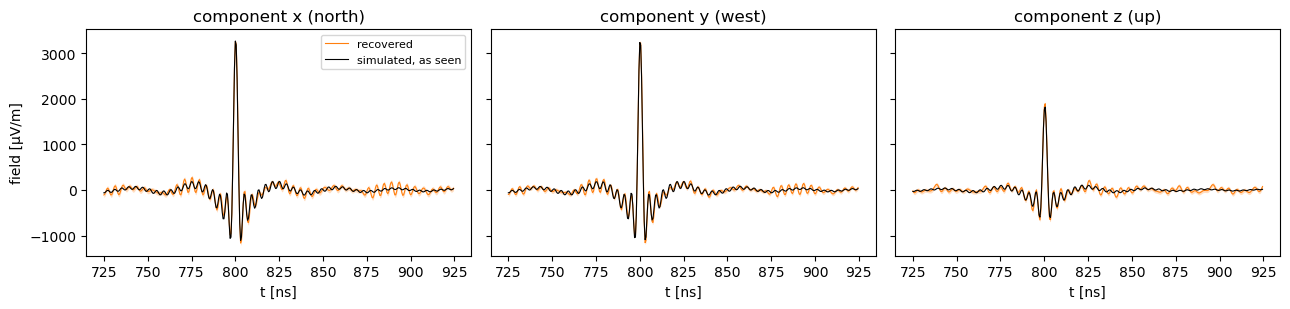

In [5]:
from grand.recon.deconvolution import WienerDeconvolution


def visible(sim, unit, response):
    """The simulated field of a unit as the antenna can see it: transverse, in the band."""
    n = response.line_of_sight
    field_f = sf.rfft(sim.traces[unit].astype(float), n=sim.fft_size, axis=1).T
    field_f = (field_f @ (np.eye(3) - np.outer(n, n))) * response.band[:, np.newaxis]
    return sf.irfft(field_f.T, n=sim.fft_size, axis=1)[:, :sim.sig_size]


truth = visible(clean, du, response)
wiener = WienerDeconvolution(np.inf, mode="transverse")
efield, sigma = wiener.deconvolve(noisy.vout[du], response, n_fft=noisy.fft_size)
print("error bar per component [µV/m]:", np.round(sigma, 1))
print("actual error, std per component [µV/m]:", np.round((efield - truth).std(axis=1), 1))

peak = np.linalg.norm(truth, axis=0).argmax()
window = slice(peak - 150, peak + 250)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for j, (ax, name) in enumerate(zip(axes, ("x (north)", "y (west)", "z (up)"))):
    ax.fill_between(t_ns[window], efield[j, window] - sigma[j], efield[j, window] + sigma[j],
                    color="C1", alpha=0.25, lw=0)
    ax.plot(t_ns[window], efield[j, window], color="C1", lw=0.8, label="recovered")
    ax.plot(t_ns[window], truth[j, window], color="k", lw=0.8, label="simulated, as seen")
    ax.set_title("component " + name)
    ax.set_xlabel("t [ns]")
axes[0].set_ylabel("field [µV/m]")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The error bars are the error actually made: both rows above should agree to a few
per cent. The pulse is recovered, but the inverse also amplifies the noise at the
edges of the band, where the antenna responds weakly.

## 5. Priors: polarization and level

Two settings reduce that noise.

**The polarization.** An air shower's field is linearly polarized along
$\vec v\times\vec B$, to within a couple of degrees on this shower's strong units.
`geomagnetic_polarization` gives that direction for a line of sight, and
`mode="polarized"` then estimates one amplitude instead of two components, from
three arms. The inclination comes from the shower tree's `magnetic_field`.

**The level.** `signal_psd="auto"` estimates one flat level per trace from its power
in excess of the noise. A single number would not do: the field's power varies by
orders of magnitude from unit to unit.

In [6]:
from grand.recon.deconvolution import geomagnetic_polarization, polarization_angle

polarization = partial(geomagnetic_polarization, zenith=clean.shower.zenith,
                       azimuth=clean.shower.azimuth,
                       inclination=float(clean.shower.magnetic_field[0]))
response = detector.response(clean.du_pos[du], clean.evt_shower, clean.freqs_mhz, noise_model,
                             polarization=polarization)       # a function of the line of sight
print("expected polarization:", np.round(response.polarization, 3),
      "angle %.1f deg" % polarization_angle(response.polarization, response.line_of_sight))
measured = np.linalg.svd(truth, full_matrices=False)[0][:, 0]
print("angle to the simulated field's main direction: %.2f deg"
      % np.degrees(np.arccos(min(abs(measured @ response.polarization), 1))))

true_peak = np.linalg.norm(truth, axis=0).max()
results = {}
print("\n%-11s %-6s %15s %13s" % ("mode", "level", "rms error", "peak / true"))
for mode in ("transverse", "polarized"):
    for level in (np.inf, "auto"):
        field, _ = WienerDeconvolution(level, mode=mode).deconvolve(
            noisy.vout[du], response, n_fft=noisy.fft_size)
        results[mode, str(level)] = field
        error = np.sqrt(np.mean(np.sum((field - truth) ** 2, axis=0)))
        print("%-11s %-6s %10.1f µV/m %13.3f"
              % (mode, level, error, np.linalg.norm(field, axis=0).max() / true_peak))

expected polarization: [-0.663 -0.657 -0.36 ] angle 111.5 deg
angle to the simulated field's main direction: 0.34 deg

mode        level        rms error   peak / true
transverse  inf          83.6 µV/m         1.001
transverse  auto         52.1 µV/m         0.835
polarized   inf          51.7 µV/m         1.002
polarized   auto         41.1 µV/m         0.901


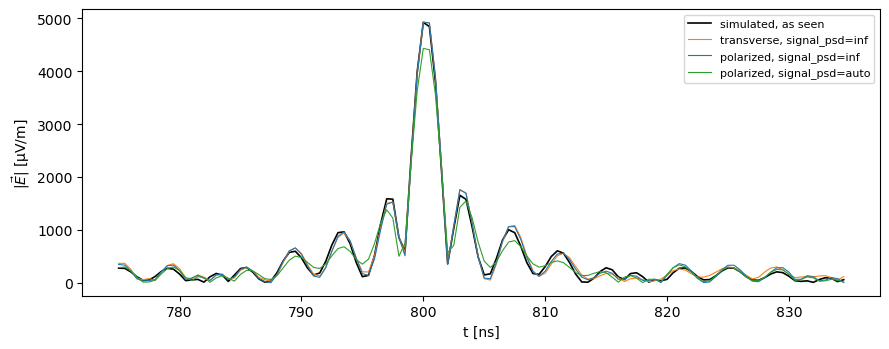

In [7]:
close = slice(peak - 50, peak + 70)                  # 60 ns around the pulse
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(t_ns[close], np.linalg.norm(truth, axis=0)[close], color="k", lw=1.2,
        label="simulated, as seen")
for (mode, level), color in zip([("transverse", "inf"), ("polarized", "inf"),
                                 ("polarized", "auto")], ("C1", "C0", "C2")):
    ax.plot(t_ns[close], np.linalg.norm(results[mode, level], axis=0)[close], color=color,
            lw=0.8, label="%s, signal_psd=%s" % (mode, level))
ax.set_xlabel("t [ns]")
ax.set_ylabel(r"$|\vec E|$ [µV/m]")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Over five noise realizations, the tests and the design note find the same
pattern on the units above a voltage signal-to-noise ratio of 15:

| | rms error, no prior | peak, no prior | rms error, `auto` | peak, `auto` |
|---|---|---|---|---|
| `transverse` | 143 µV/m | +1.4 % | 36 µV/m | −20 % |
| `polarized` | 53 µV/m | +0.5 % | 28.5 µV/m | −12 % |

So: `polarized` helps in every case. **No prior** is the choice when the peak
matters; `auto` when the overall error does. A flat level lowers the peak because
the filter treats the signal as stationary and does not know it is a short pulse;
a shaped prior on the spectrum, such as J.-M. Colley's ePSD model, is the planned
remedy.

The third mode, `"full3d"`, puts no assumption on the polarization. Since the
antenna does not see the line of sight, it needs a finite prior; without one it
warns and returns zeros.

## 6. Under the hood: the spectrum, and a measured noise

`deconvolve` wraps `deconvolve_spectrum`, which works on the rFFT and returns the
field spectrum, the variance of each bin and the bins that were estimated. The
error bar in time is `time_variance` of that variance.

In [8]:
from grand.recon.deconvolution.base import time_variance

result = WienerDeconvolution(np.inf, mode="polarized").deconvolve_spectrum(noisy.vout_f[du].T,
                                                                         response)
print(type(result).__name__, "with efield", result.efield.shape, "variance",
      result.variance.shape, "valid", result.valid.shape)
print("estimated: %d bins, %.1f to %.1f MHz"
      % (result.valid.sum(), clean.freqs_mhz[result.valid][0], clean.freqs_mhz[result.valid][-1]))
print("error bar in time, per component [µV/m]:",
      np.round(np.sqrt(time_variance(result.variance, noisy.fft_size)), 2))

DeconvolvedSpectrum with efield (4097, 3) variance (4097, 3) valid (4097,)
estimated: 901 bins, 30.0 to 249.8 MHz
error bar in time, per component [µV/m]: [33.2  32.91 18.03]


In measured data the noise model is better estimated from the data than taken
from the Galactic model, which leaves out the electronics. `MeasuredNoise` does that
from noise-only traces: here, the noise the simulation drew, as forced triggers
would give it.

Its `n_segment` sets the frequency resolution of the estimate, and it matters at the
edges of the band, where the noise changes by orders of magnitude within a few MHz.
Too short a segment smears it there, and inflates the error bar:

In [9]:
from grand.recon.deconvolution import MeasuredNoise

wiener = WienerDeconvolution(np.inf, mode="polarized")
reference, _ = wiener.deconvolve(noisy.vout[du], response, n_fft=noisy.fft_size)
edge = band & (clean.freqs_mhz < 32)
models = [("GalacticNoise", noise_model)] + [
    ("MeasuredNoise, %d" % n, MeasuredNoise(noise_only, clean.dt_ns[0], n_segment=n))
    for n in (512, 2048)]
for name, model in models:
    unit = detector.response(clean.du_pos[du], clean.evt_shower, clean.freqs_mhz, model,
                             polarization=polarization)
    field, sigma = wiener.deconvolve(noisy.vout[du], unit, n_fft=noisy.fft_size)
    print("%-20s noise at 30-32 MHz x%-6.1f error bar %6.1f µV/m   field moves by %.1f%% of its peak"
          % (name, np.median(unit.noise_psd[edge, 0] / response.noise_psd[edge, 0]),
             np.linalg.norm(sigma), 100 * np.abs(field - reference).max() / np.abs(reference).max()))

GalacticNoise        noise at 30-32 MHz x1.0    error bar   50.1 µV/m   field moves by 0.0% of its peak
MeasuredNoise, 512   noise at 30-32 MHz x434.4  error bar  427.0 µV/m   field moves by 0.3% of its peak
MeasuredNoise, 2048  noise at 30-32 MHz x1.1    error bar   51.4 µV/m   field moves by 0.2% of its peak


With segments of 2048 samples, 1 MHz at this sampling, the measured noise is the
model's and so is the error bar. The field itself hardly moves either way: the
noise model mostly decides how the arms are weighed, and the error bar.

# Part II — the AOI interface

## 7. An event from files

`EventDeconvolver` does all of Part I for every unit of an `Event`. To use it as on
real files, we write the noisy voltage next to the sample's efield, run and shower
files, and read the folder back with `EventList`.

Read **one analysis level**, with `DataDirectory(folder, analysis_level=...)`.
Section 9 shows why.

In [10]:
from grand.aoi import EventList
from grand.dataio import DataDirectory

folder = pathlib.Path(tempfile.mkdtemp())
for path in SAMPLE.glob("*_L0_*.root"):
    if not path.name.startswith("voltage"):
        os.symlink(path, folder / path.name)
writer = Efield2Voltage(str(SAMPLE), "voltage_1618-13790_L0_0000.root",
                        output_directory=str(folder), seed=1, efield_level=0)
writer.params.update(add_noise=True, add_rf_chain=True, lst=LST)
writer.compute_voltage(event_idx=0)          # computes the voltage and writes the file
print(sorted(path.name for path in folder.iterdir()))

event = next(iter(EventList(DataDirectory(str(folder), analysis_level=0))))
print("event %d: %d voltages, sampled at %.1f ns; reconstructed shower: %s, simulated: %s"
      % (event.event_number, len(event.voltages), event.voltages[0].t_bin_size,
         event.shower is not None, event.simshower is not None))

['efield_1618-13790_L0_0000.root', 'run_1_L0_0000.root', 'runefieldsim_1_L0_0000.root', 'runshowersim_1_L0_0000.root', 'shower_1618-13790_L0_0000.root', 'showersim_1618-13790_L0_0000.root', 'voltage_1618-13790_L0_0000.root']
event 13790: 44 voltages, sampled at 0.5 ns; reconstructed shower: False, simulated: True


## 8. Deconvolving the event

The method is given as an object, with its settings; the noise model and which
shower gives the geometry are the deconvolver's. A simulation folder at level 0
has only the simulated shower, so `shower="simshower"`; on data, the reconstructed
`"shower"` is the default.

In [11]:
from grand.recon.deconvolution import EventDeconvolver

deconvolver = EventDeconvolver(WienerDeconvolution(np.inf, mode="polarized"),
                               GalacticNoise(lst=LST), shower="simshower",
                               antenna_model=clean.ant_model)
result = deconvolver.deconvolve_event(event)

print(type(result).__name__)
for name in ("du_id", "sigma", "polarization", "polarization_angle", "band_mhz"):
    print("  %-19s %s" % (name, getattr(result, name).shape))
field = result.efields[0]
print("efields: %d %s, e.g. du_id %d: %s samples of %.1f ns, t0 %s"
      % (len(result.efields), type(field).__name__, field.du_id,
         np.asarray(field.trace).shape, field.t_bin_size, field.t0))
print("expected polarization angle: %.1f to %.1f deg"
      % (np.nanmin(result.polarization_angle), np.nanmax(result.polarization_angle)))

EventDeconvolution
  du_id               (44,)
  sigma               (44, 3)
  polarization        (44, 3)
  polarization_angle  (44,)
  band_mhz            (44, 2)
efields: 44 Efield, e.g. du_id 46: (3, 8192) samples of 0.5 ns, t0 1976-05-13T17:01:59.999986677
expected polarization angle: 111.0 to 111.7 deg


The fields are `grand.aoi.Efield` objects on the time axis of the voltages, in
µV/m, in the shower frame (x north, y west, z up, from magnetic north). The event is
left as it was: `event.efields` still holds the simulated fields, and the result
outlives the `Event` that `EventList` refills for the next one. Nothing is written
to file.

Against the truth, unit by unit:

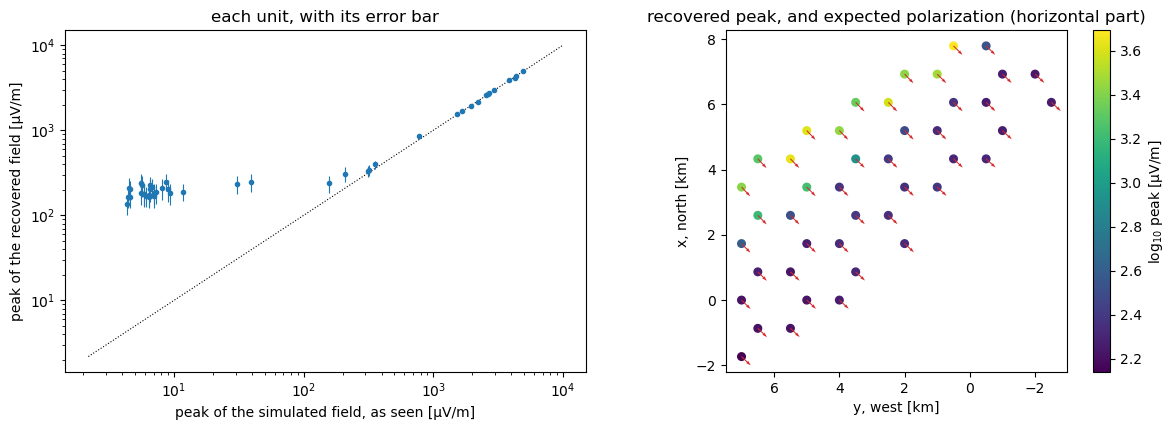

16 units whose field stands above 5 error bars: recovered peak / true, median 1.007, from 0.972 to 1.109
the other 28: recovered peak / error bar, median 3.8 -- the peak of the noise


In [12]:
by_id = {int(i): k for k, i in enumerate(clean.du_id)}
recovered, expected, error_bar = [], [], []
for k, unit in enumerate(result.du_id):
    sim_index = by_id[int(unit)]
    unit_response = detector.response(clean.du_pos[sim_index], clean.evt_shower,
                                      clean.freqs_mhz, noise_model)
    recovered.append(np.linalg.norm(np.asarray(result.efields[k].trace), axis=0).max())
    expected.append(np.linalg.norm(visible(clean, sim_index, unit_response), axis=0).max())
    error_bar.append(np.linalg.norm(result.sigma[k]))
recovered, expected, error_bar = map(np.array, (recovered, expected, error_bar))

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.4))
left.errorbar(expected, recovered, yerr=error_bar, fmt="o", ms=3, lw=0.8)
line = [expected.min() / 2, expected.max() * 2]
left.plot(line, line, "k:", lw=0.8)
left.set_xscale("log"); left.set_yscale("log")
left.set_xlabel("peak of the simulated field, as seen [µV/m]")
left.set_ylabel("peak of the recovered field [µV/m]")
left.set_title("each unit, with its error bar")

positions = np.array([np.ravel(a.position) for a in event.antennas])
scale = right.scatter(positions[:, 1] / 1e3, positions[:, 0] / 1e3, c=np.log10(recovered),
                      cmap="viridis", s=30)
right.quiver(positions[:, 1] / 1e3, positions[:, 0] / 1e3, result.polarization[:, 1],
             result.polarization[:, 0], angles="xy", scale=25, width=0.003, color="C3")
right.invert_xaxis()
right.set_aspect("equal")
right.set_xlabel("y, west [km]")
right.set_ylabel("x, north [km]")
right.set_title("recovered peak, and expected polarization (horizontal part)")
fig.colorbar(scale, ax=right, label=r"log$_{10}$ peak [µV/m]")
fig.tight_layout()
plt.show()
strong = expected > 5 * error_bar
print("%d units whose field stands above 5 error bars: recovered peak / true, median %.3f, from %.3f to %.3f"
      % (strong.sum(), np.median(recovered[strong] / expected[strong]),
         (recovered[strong] / expected[strong]).min(), (recovered[strong] / expected[strong]).max()))
print("the other %d: recovered peak / error bar, median %.1f -- the peak of the noise"
      % ((~strong).sum(), np.median(recovered[~strong] / error_bar[~strong])))

Strong units sit on the diagonal. Weak ones lie above it: there, what an
unregularized inverse returns as a peak is the largest excursion of the noise over
thousands of samples, a few error bars, whatever the field. For those,
`signal_psd="auto"` or a selection on the signal-to-noise ratio is the way.

## 9. Pitfalls

**A folder of several analysis levels.** The AOI reads a voltage's sampling from
the run tree. In a folder holding levels 0 and 1, the run tree is level 1's
(2 ns) while the voltage is level 0's (0.5 ns); the field would come out about 300
times too large. `deconvolve_event` refuses it:

In [13]:
mixed = next(iter(EventList(str(SAMPLE))))
print("run tree level %d, voltage level %d, Voltage.t_bin_size = %s ns"
      % (mixed.trun.analysis_level, mixed.tvoltage.analysis_level, mixed.voltages[0].t_bin_size))
try:
    deconvolver.deconvolve_event(mixed)
except ValueError as error:
    print("\nValueError:", error)

run tree level 1, voltage level 0, Voltage.t_bin_size = 2.0 ns

ValueError: GRANDlib: EventDeconvolver.deconvolve_event: the voltages are of analysis level 0 and the run tree, which gives their sampling (2.0 ns), of level 1. Read one level, with EventList(DataDirectory(folder, analysis_level=0)), or give the sampling with EventDeconvolver(t_bin_ns=...)


The way out is to read one level, as in section 7, or to give the sampling with
`EventDeconvolver(t_bin_ns=0.5)`. The same problem affects `Efield.t_bin_size`,
which reading never sets: it stays at the default 2 ns.

Others to keep in mind:

- **Units.** The voltages must be in µV. `TRawVoltage` and ADC counts are not;
  their conversion is not part of this package.
- **The same models.** The response must be that of the chain the voltages went
  through: `du_type`, `rf_chain` and the VGA gain. The 2024 voltage file of section
  1 shows what happens otherwise.
- **The geometry.** It comes from the event's shower: `Xmaxpos`, zenith, azimuth
  and core, and `magnetic_field` for the polarization. An event without a usable
  Xmax is refused; one without a magnetic field gets no expected polarization, and
  `inclination=` can supply it.

## 10. Bringing your own method

`EventDeconvolver` takes any subclass of `Deconvolution`. A method implements one
function, `deconvolve_spectrum(voltage_f, response)`, and returns a
`DeconvolvedSpectrum`; the time domain, the response and the AOI come for free.

As an example, the "no Wiener" mode of J.-M. Colley's 2025 slides: along the
expected polarization, divide the voltage of the single arm that responds best.

In [14]:
from grand.recon.deconvolution import Deconvolution, DeconvolvedSpectrum


class BestArmInverse(Deconvolution):
    """Divides the arm with the largest response along the expected polarization."""

    def deconvolve_spectrum(self, voltage_f, response):
        gain = response.transfer @ response.polarization                 # (n_freq, 3)
        valid = response.band & np.any(gain != 0, axis=1)
        arm = np.argmax(np.sum(np.abs(gain[valid]) ** 2, axis=0))
        amplitude = np.zeros(response.n_freq, dtype=complex)
        variance = np.zeros(response.n_freq)
        amplitude[valid] = voltage_f[valid, arm] / gain[valid, arm]
        variance[valid] = response.noise_psd[valid, arm] / np.abs(gain[valid, arm]) ** 2
        p = response.polarization
        return DeconvolvedSpectrum(efield=np.outer(amplitude, p),
                                   variance=np.outer(variance, p ** 2), valid=valid)


best_arm = EventDeconvolver(BestArmInverse(), GalacticNoise(lst=LST), shower="simshower",
                            antenna_model=clean.ant_model).deconvolve_event(event)
strongest = int(np.argmax(expected))
for name, outcome in (("BestArmInverse", best_arm), ("Wiener, polarized", result)):
    print("%-18s error bar on the strongest unit: %.1f µV/m"
          % (name, np.linalg.norm(outcome.sigma[strongest])))

BestArmInverse     error bar on the strongest unit: 61.4 µV/m
Wiener, polarized  error bar on the strongest unit: 50.1 µV/m


Combining the three arms, as the Wiener filter does, gives the smaller error bar:
it weighs each arm by what it sees against its noise.

## 11. What to trust

| | Status |
|---|---|
| Transfer matrix | the simulation's own code; matches its voltages to $10^{-7}$ |
| Noiseless round trip | the field comes back to $10^{-5}$ of the peak, in the band and transverse |
| Error bars | the error made, to a few per cent, on this shower |
| Expected polarization | within 1.9° of the simulated field on its 18 strong units |
| Other geometries, other showers | **not tested**: one shower, zenith 79° |
| Measured data | **not tested**; needs ADC counts in µV first |
| Peak with a finite prior | biased low, by design of a flat prior |

The tests are in `tests/recon/`; the design, with the measurements behind these
numbers, in the package's design note.

## Where next

- [03 — The antenna response](03_antenna_response.ipynb) — the effective length this inverts
- [05 — Galactic noise](05_galactic_noise.ipynb) — the noise model behind `GalacticNoise`
- [09 — Reading events](09_reading_events.ipynb) — `grand.aoi`, which Part II reads through
- [11 — Reconstructing a shower](11_reconstruction.ipynb) — direction, Xmax and energy, which the geometry here could come from

<!-- provenance -->
---

*Generated by `notebooks/make_notebooks.py` on 2026-11-09 23:31 UTC, from commit `21638263` plus the changes being committed with it, running Python 3.12.16. Edit the generator and rebuild rather than editing this file: a notebook edited in place is overwritten by the next build, and `--check` will say so.*